# NAV EDA — SBI & HDFC Tier I (E / C / G)

Real NPS scheme-wise NAV history from npsnav.in (see `docs/data_sources.md`). Loads the cleaned
`data/processed/nav_returns.parquet` produced by `src/data/clean_nav.py` and sanity-checks it before
it feeds the Day 5 Monte Carlo bootstrap.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/nav_returns.parquet")
df.head()

Matplotlib is building the font cache; this may take a moment.


,date,pfm,scheme_class,scheme_code,nav,log_return
0,2009-05-05,SBI,E,SM001003,10.0,NaN
1,2009-05-06,SBI,E,SM001003,10.0,0.0
2,2009-05-07,SBI,E,SM001003,10.0,0.0
3,2009-05-08,SBI,E,SM001003,10.0,0.0
4,2009-05-11,SBI,E,SM001003,10.0,0.0


## NAV series over time, per PFM × scheme class

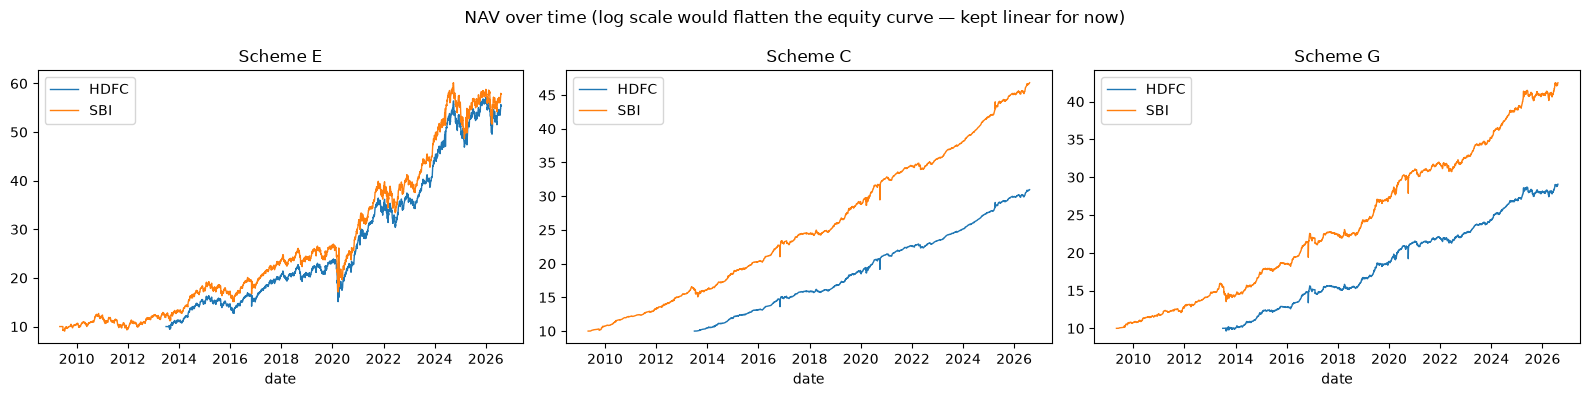

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, scheme_class in zip(axes, ["E", "C", "G"]):
    for pfm, g in df[df.scheme_class == scheme_class].groupby("pfm"):
        ax.plot(g["date"], g["nav"], label=pfm, linewidth=1)
    ax.set_title(f"Scheme {scheme_class}")
    ax.legend()
    ax.set_xlabel("date")
fig.suptitle("NAV over time (log scale would flatten the equity curve — kept linear for now)")
plt.tight_layout()
plt.show()

## Daily log-return distributions

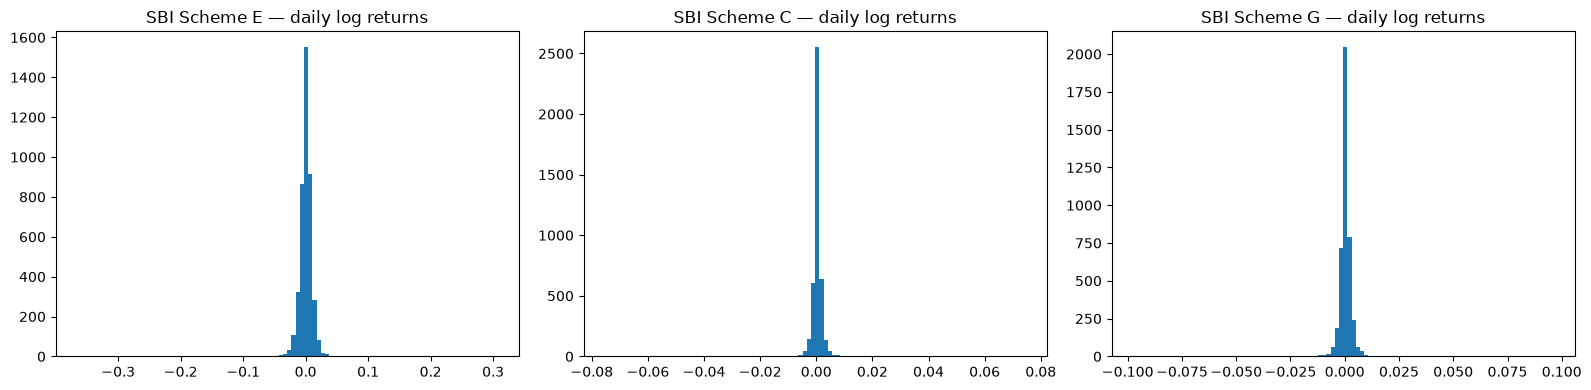

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, scheme_class in zip(axes, ["E", "C", "G"]):
    sub = df[(df.scheme_class == scheme_class) & (df.pfm == "SBI")]["log_return"].dropna()
    ax.hist(sub, bins=100)
    ax.set_title(f"SBI Scheme {scheme_class} — daily log returns")
plt.tight_layout()
plt.show()

## Annualized mean / vol summary

Sanity check: equity should show the highest return and vol, gov securities the lowest vol, corporate
debt in between — matches published NPS scheme characteristics if the data pull is correct.

In [4]:
rows = []
for (pfm, scheme_class), g in df.groupby(["pfm", "scheme_class"]):
    r = g["log_return"].dropna()
    rows.append({
        "pfm": pfm, "scheme_class": scheme_class,
        "start": g["date"].min().date(), "end": g["date"].max().date(), "n_obs": len(g),
        "annualized_mean_return": r.mean() * 252,
        "annualized_vol": r.std() * np.sqrt(252),
    })
summary = pd.DataFrame(rows).sort_values(["pfm", "scheme_class"]).reset_index(drop=True)
summary

,pfm,scheme_class,start,end,n_obs,annualized_mean_return,annualized_vol
0,HDFC,C,2013-07-01,2026-08-10,3182,0.089528,0.051621
1,HDFC,E,2013-07-01,2026-08-10,3182,0.135638,0.221781
2,HDFC,G,2013-07-01,2026-08-10,3182,0.084539,0.065887
3,SBI,C,2009-05-05,2026-08-10,4231,0.091961,0.048320
4,SBI,E,2009-05-05,2026-08-10,4231,0.104496,0.201370
5,SBI,G,2009-05-05,2026-08-10,4231,0.086194,0.061282


## Cross-PFM correlation (same scheme class)

Relevant for the Day 5 decision on whether to bootstrap SBI/HDFC jointly or separately: if the two
PFMs' returns for the same scheme class are highly correlated (expected, both track similar underlying
asset classes), blending them for a larger bootstrap sample is defensible.

In [5]:
wide = df.pivot_table(index="date", columns=["pfm", "scheme_class"], values="log_return")
overlap = wide.dropna()
print(f"overlapping window: {overlap.index.min().date()} -> {overlap.index.max().date()}, n={len(overlap)}")
corr = overlap.corr()
corr

overlapping window: 2013-07-02 -> 2026-08-10, n=3181


pfm                    HDFC                           SBI                    
scheme_class              C         E         G         C         E         G
pfm  scheme_class                                                            
HDFC C             1.000000  0.057685  0.844548  0.915189  0.058316  0.807907
     E             0.057685  1.000000  0.110982  0.076454  0.994544  0.117522
     G             0.844548  0.110982  1.000000  0.855166  0.112077  0.964841
SBI  C             0.915189  0.076454  0.855166  1.000000  0.082356  0.885143
     E             0.058316  0.994544  0.112077  0.082356  1.000000  0.123320
     G             0.807907  0.117522  0.964841  0.885143  0.123320  1.000000